In [42]:
#installs requirement for correlation heatmap (style)
%pip install -r requirements.txt


[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [43]:
import pandas as py
import numpy as np
import yfinance as yf
print( yf.__version__ )
tickers = ['SPY','QQQ','IWM','EFA','EEM','TLT','IEF','LQD','GLD','DBC','VNQ'] #chooses ETFs from Yahoo Finance
prices = yf.download(tickers, start='2007-01-01', auto_adjust=True)['Close'] # downloads (close) data from 2007 to date
prices.head()

1.8.0


[*********************100%***********************]  11 of 11 completed


Ticker,DBC,EEM,EFA,GLD,IEF,IWM,LQD,QQQ,SPY,TLT,VNQ
Date,,,,,,,,,,,
2007-01-03,19.330030,25.692627,41.088036,62.279999,49.620365,60.121063,48.489727,37.000309,98.624619,47.655071,34.003273
2007-01-04,18.826475,25.337830,40.970673,61.650002,49.800411,60.282566,48.854134,37.702000,98.833908,47.943989,34.047367
2007-01-05,18.761501,24.596991,40.355808,60.169998,49.638382,59.021072,48.822247,37.522301,98.045578,47.735340,33.416859
2007-01-08,18.858963,24.775511,40.411720,60.480000,49.674389,58.790306,48.808571,37.547974,98.499062,47.820950,33.465355
2007-01-09,18.696527,24.222116,40.450848,60.849998,49.662350,59.344170,48.817657,37.736210,98.415268,47.820950,33.888630


In [44]:
print(prices.shape)
print(prices.index.min(), prices.index.max())
print(prices.isna().sum())



(5006, 11)
2007-01-03 00:00:00 2026-11-24 00:00:00
Ticker
DBC    0
EEM    0
EFA    0
GLD    0
IEF    0
IWM    0
LQD    0
QQQ    0
SPY    0
TLT    0
VNQ    0
dtype: int64


<Axes: title={'center': 'ETF prices rebased to 100'}, xlabel='Date'>

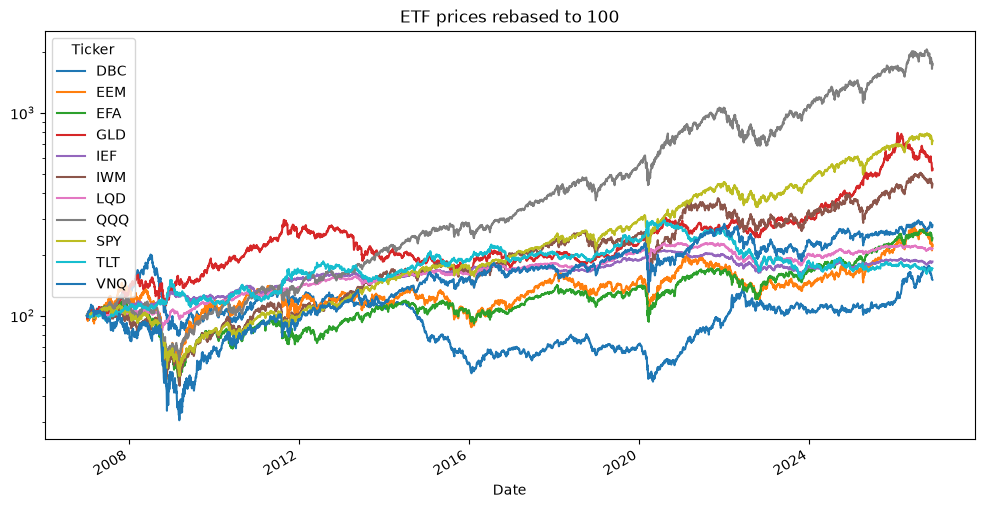

In [45]:
rebased = prices / prices.iloc[0]*100
rebased.plot(figsize=(12,6), title = 'ETF prices rebased to 100',logy=True)


In [46]:
p2008 = prices.loc['2008-01-01':'2008-12-31']
(p2008.iloc[-1]/p2008.iloc[0]-1)*100

Ticker
DBC   -33.628847
EEM   -48.021170
EFA   -40.819975
GLD     1.956158
IEF    17.083143
IWM   -33.492292
LQD     1.225844
QQQ   -40.790790
SPY   -36.236821
TLT    32.049990
VNQ   -36.786825
dtype: float64

We have taken the data from 11 ETF's from the start to date. We have chosen to focus on the data at close because it will give the best indication of change in value over time. A log plot has been used because QQQ was making the rest of the data appear compressed hence it was hard to view. I decided to investigate the annual change in the value of all the ETFs in 2008 because I was surprised to see that some didn't fall.

In [47]:
#Volatility
daily_returns = rebased.pct_change()
daily_returns.head()
daily_returns = daily_returns.iloc[1:]


In [48]:
#finds the percent change of rebased prices from the end of every month compared to the previous month
monthly_returns = rebased.resample('ME').last()
monthly_returns = monthly_returns.pct_change().iloc[1:]

In [49]:
#finds annual return and volatility using average number of trading days per year
days_total = rebased.groupby(rebased.index.year).size()
avg_days = days_total.iloc[:-1].mean() #mention in README because most reports use 252 days
annual_returns = daily_returns.mean()*avg_days
annual_volatility = daily_returns.std()*avg_days**0.5
print((annual_returns*100.).round(1))
print((annual_volatility*100.).round(1))   

Ticker
DBC     3.9
EEM     7.9
EFA     6.7
GLD    10.0
IEF     3.3
IWM    10.5
LQD     4.2
QQQ    16.8
SPY    11.9
TLT     3.8
VNQ     9.5
dtype: float64
Ticker
DBC    19.3
EEM    28.0
EFA    21.5
GLD    18.3
IEF     6.9
IWM    24.6
LQD     8.7
QQQ    22.3
SPY    19.6
TLT    15.0
VNQ    29.3
dtype: float64


In [50]:
#finding correlations using daily returns
correlations = daily_returns.corr()
correlations.round(2).style.background_gradient(cmap='coolwarm', vmin=-1, vmax=1)

Ticker,DBC,EEM,EFA,GLD,IEF,IWM,LQD,QQQ,SPY,TLT,VNQ
Ticker,,,,,,,,,,,
DBC,1.000000,0.430000,0.430000,0.330000,-0.210000,0.360000,0.060000,0.310000,0.390000,-0.240000,0.260000
EEM,0.430000,1.000000,0.870000,0.190000,-0.260000,0.760000,0.180000,0.770000,0.820000,-0.260000,0.650000
EFA,0.430000,0.870000,1.000000,0.170000,-0.260000,0.810000,0.230000,0.780000,0.880000,-0.280000,0.690000
GLD,0.330000,0.190000,0.170000,1.000000,0.220000,0.070000,0.160000,0.070000,0.070000,0.160000,0.060000
IEF,-0.210000,-0.260000,-0.260000,0.220000,1.000000,-0.270000,0.570000,-0.250000,-0.290000,0.910000,-0.150000
IWM,0.360000,0.760000,0.810000,0.070000,-0.270000,1.000000,0.170000,0.820000,0.890000,-0.290000,0.760000
LQD,0.060000,0.180000,0.230000,0.160000,0.570000,0.170000,1.000000,0.180000,0.200000,0.550000,0.180000
QQQ,0.310000,0.770000,0.780000,0.070000,-0.250000,0.820000,0.180000,1.000000,0.920000,-0.250000,0.620000
SPY,0.390000,0.820000,0.880000,0.070000,-0.290000,0.890000,0.200000,0.920000,1.000000,-0.300000,0.740000


#worth mentioning that corrleated ETFs carry simmilar risk (buying them is like making the same trade)

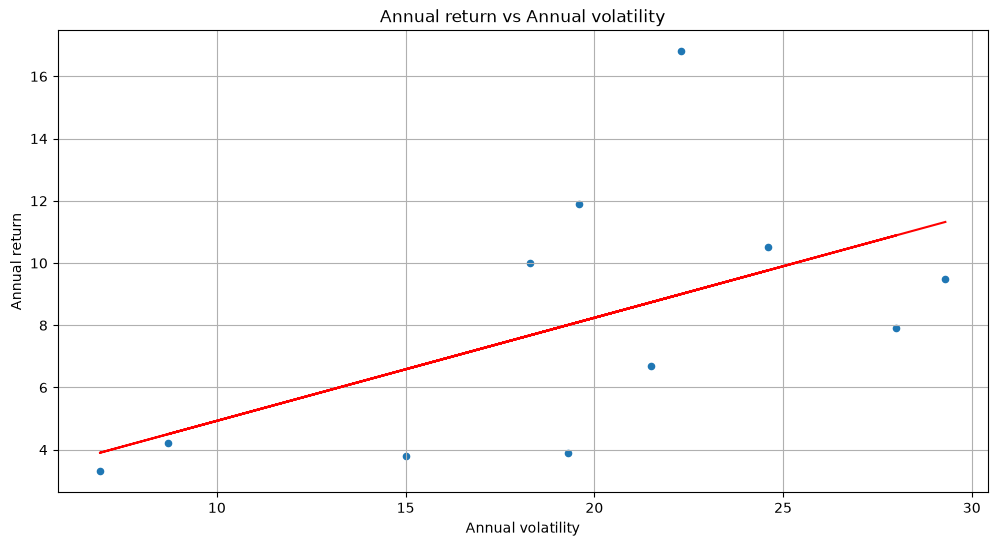

In [51]:
#table of annual returns and volatility
summary = py.DataFrame({"Annual return %": annual_returns*100, "Annual volatility %": annual_volatility*100}).round(1)
summary.sort_values("Annual volatility %", ascending = True)
ax = summary.plot.scatter(x="Annual volatility %", y="Annual return %", figsize = (12,6), title = 'Annual return vs Annual volatility', xlabel = 'Annual volatility', ylabel = 'Annual return', grid = True)
x = summary["Annual volatility %"]
slope, intercept = np.polyfit(x, summary["Annual return %"], 1)
ax.plot(x, slope*x + intercept, color='red', label='Trend line')

We found the volatility (risk) by calculating the percent change at close day on day. To find the annual average we multiplied it by the average number of trading days per year (we excluded 2026 when finding average days because it's the current/incomplete year). We have also created a table (above) which used this to show annual return vs volatility (Volatility calculated as daily standard deviatin x sqrt(avg days)).
I created the graph and line of best fit to highlight the observation that higher annual volatility tends to come with higher return (Points above the line perform well).
Returning to the table it's worth noting that Bond ETFs like IEF have far lower volatility compared to equity ETFs like QQQ (as we'd expect). Stocks vs Bonds is a choice of potential return vs risk and the best traders will cover their downsides whilst making a healthy upside from a balance of different investments.
The correlation table is very valuable because it shows that some investments are almost redundant (if two are extremely simmilar). We can see that QQQ and SPY have the highest correlation of 0.92 (Because they are both large stock indices and are weighted heavily towards the same companies). Holding two extremely correlated options offers little diversification.

In [52]:
#calulates the annual return over the last 12 months to help us pick which ETSs to buy
signal = (monthly_returns+1).rolling(12).apply(lambda x: x.prod(),raw = True)-1

#picks the top 3 returners over the last 12 months
rank = signal.rank(axis = 1, ascending = False)
picks = ( rank <= 3).astype(int)
#axis = 0 works down rows and treats columns seperately
#axis = 1 works across columns and treats rows seperately


#calculates the average monthly return if we held the top 3 equally over the following month (worth assesing weighting?)
held = picks.shift(1)
strategy_returns = (held*monthly_returns).sum(axis = 1)/3
strategy_returns = strategy_returns.iloc[12:]

#gives us our strategy curve which shows how our investments grow month on month
strategy_curve = (1+strategy_returns).cumprod()

We will compare it to SPY which is an investment in the top 500 USA companies and an equal weight choice in all ETFs. These seem like good benchmarks to set it against.
In hindsight we know QQQ returned the best but we have to compare our startegy to a choice we could have realistically made when the strategy began.

In [53]:
#create the benchmarks
spy = monthly_returns['SPY'].loc[strategy_returns.index]
equal_weight = monthly_returns.mean(axis = 1).loc[strategy_returns.index]

spy_curve = (1+spy).cumprod()
equal_weight_curve = (1+equal_weight).cumprod()

Momentum top 3    3.525022
SPY               7.364358
Equal Weight      3.494923
Name: 2026-11-30 00:00:00, dtype: float64

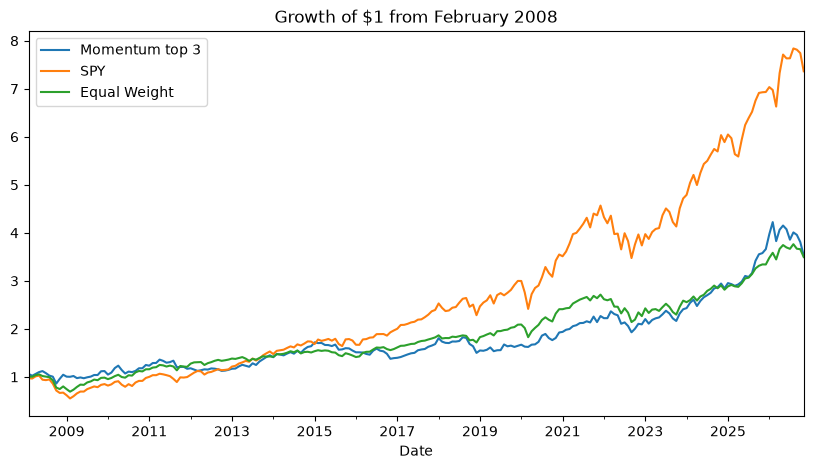

In [54]:
#plot them all against eachother
curves = py.DataFrame({"Momentum top 3": strategy_curve, "SPY": spy_curve, "Equal Weight": equal_weight_curve})
curves.plot(figsize=(10,5), title = "Growth of $1 from February 2008")
curves.iloc[-1]

What the strategy does: At the end of every month we look at the previous 12 months of data and analyse which have been the top 3 performers. We then purchase these 3 ETS's (weighted equally) at the start of the next month and hold them for 1 month before repeating the process.
I avoided look ahead bias by shifting the rows so that the decision was made purely on past data.
The chart above shows that to data one dollar in equal weighting across all ETSs turned our $1 into $3.51 and our strategy turned it into $3.52. This is basically the same, and observing that the line for our strategy actually spent a lot of time below the equal weight line indicated that our strategy actually performed worse for a lot of the duration.
This version also leaves out trading costs.
(Worth noting that the final month is partial because we are only part way thorugh our current month)

In [58]:
#calculates the costs associated with buying/selling (assuming selling or buying a portfolio costs 0.1% of how much you're investing)
weights = held.div(held.sum(axis = 1), axis = 0).fillna(0)
turnover = weights.diff().abs().sum(axis=1)

turnover = turnover[12:]
costs = 0.001*turnover
net_returns = (1+strategy_returns)*(1-costs)-1
net_curve = (1+net_returns).cumprod()

Momentum top 3 (net)    3.177753
SPY                     7.364358
Equal Weight            3.494923
Name: 2026-11-30 00:00:00, dtype: float64

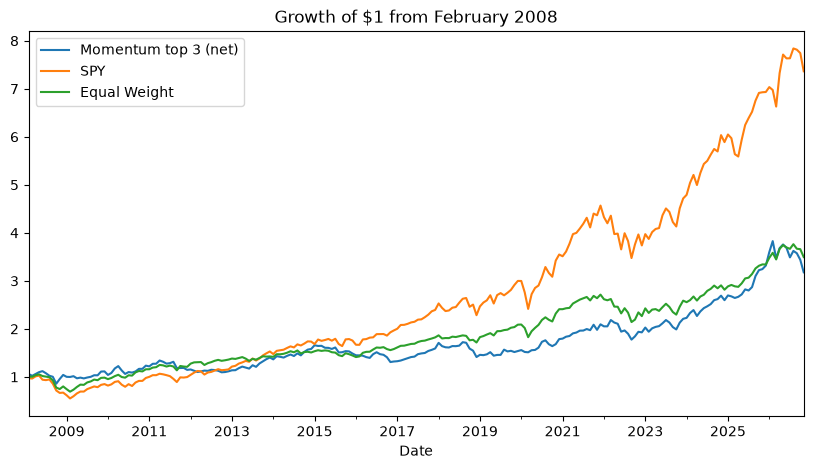

In [59]:
#plot them all against eachother
net_curves = py.DataFrame({"Momentum top 3 (net)": net_curve, "SPY": spy_curve, "Equal Weight": equal_weight_curve})
net_curves.plot(figsize=(10,5), title = "Growth of $1 from February 2008")
net_curves.iloc[-1]


In [60]:
#Headline cost (Gross-Net)
gross = strategy_curve.iloc[-1]
net = net_curve.iloc[-1]
print(f"Gross: ${gross:.2f} Net: ${net:.2f}")

Gross: $3.53 Net: $3.18


The graph above has factored in trading costs assumed to be 0.1% of an investment's value whenever bought or sold. As we can see this effect has compounded and taken our end value from $3.53 to $3.18. It should be noted that our costs were not weighted for each portfolio and instead taken as a fraction of the total value of our investment simply based on how ETF changes were made.